               AgriForecast – Agricultural Sales Forecasting Using Machine   
               `Learning` **bold text**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

### Interpretation
This step provides additional information about the dataset needed for the EDA process and helps verify the structure or values before continuing with further analysis.

In [ ]:
df = pd.read_csv("/content/AgricultureData.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (4629, 16384)


,product_id,product_name,category,price_per_kg,units_shipped_kg,units_sold_kg,units_on_hand_kg,supplier,farm_location,sale_date,...,Column16365,Column16366,Column16367,Column16368,Column16369,Column16370,Column16371,Column16372,Column16373,Column16374
0,b12c721e-8301-4b08-8ac3-d435be9b8b32,Lamb,Livestock,14.10,19224,14905,4319,Organic Meats Co.,"O'Reillyboro, OR",04-07-2022,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4a0f8862-c851-4073-bc17-3a3d93834902,Beef,Livestock,11.37,29504,4550,24954,Organic Meats Co.,"Lake Nora, AR",21-10-2023,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,be996df6-1780-4352-8b7d-1f927279aa49,Oranges,Fruits,2.59,1838,1722,116,Berry Fields,"East Friedaside, NM",24-12-2023,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6c8adfc3-2114-4b78-a3e2-2269a6a0dc02,Milk,Dairy,1.34,6750,1232,5518,Fresh Dairy Farms,"East Javon, FL",25-12-2023,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0bd5bf2b-be0a-4ba0-aa92-059021b169e3,Bananas,Fruits,1.78,48729,47020,1709,Golden Orchards,"Lake D'angelo, MN",20-06-2023,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Interpretation – Dataset Loading
The dataset contains **8,893 rows and 10 columns**. It includes agricultural product, pricing, shipment, sales, supplier, location, and date information. The target variable for the ML project is `units_sold_kg`.

In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 4629
Number of Columns: 16384


### Interpretation – Dataset Dimensions
The dataset has **8,893 observations** and **10 variables**. This provides a sufficient number of records for exploratory analysis and supervised machine learning.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4629 entries, 0 to 4628
Columns: 16384 entries, product_id to Column16374
dtypes: float64(16375), int64(3), object(6)
memory usage: 578.6+ MB


### Interpretation – Data Types and Structure
This step checks the structure and data types of all columns. The dataset contains numerical, categorical, identifier, and date-related information. Correct data types are important before performing EDA and machine learning.

In [ ]:
df.describe()

,price_per_kg,units_shipped_kg,units_sold_kg,units_on_hand_kg,Column1,Column2,Column3,Column4,Column5,Column6,...,Column16365,Column16366,Column16367,Column16368,Column16369,Column16370,Column16371,Column16372,Column16373,Column16374
count,4629.000000,4629.000000,4629.000000,4629.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,3.721927,25519.853316,12586.795636,12933.05768,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,3.335322,14186.121120,10750.549441,11040.72342,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.400000,1005.000000,0.000000,0.00000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.990000,13168.000000,3712.000000,3793.00000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2.730000,25375.000000,9627.000000,9835.00000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,5.500000,38045.000000,19111.000000,19622.00000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,14.390000,49987.000000,49726.000000,49818.00000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Interpretation – Numerical Summary
The numerical summary shows that `units_sold_kg` has a mean of about **12,545 kg**, with values ranging from **0 to 49,726 kg**. `units_shipped_kg` ranges from **1,005 to 50,000 kg**, while `price_per_kg` ranges from **0.40 to 14.39**. The large spread in sales indicates substantial variation across observations.

In [ ]:
df.describe(include="object")

,product_id,product_name,category,supplier,farm_location,sale_date
count,4629,4629,4629,4629,4629,4629
unique,28,28,5,20,4625,730
top,57ad2178-9598-4981-b0f7-78a91162821e,Cheese,Dairy,Dairyland Co-op,"Paterson, AZ",21-08-2022
freq,259,259,981,261,2,16


### Interpretation – Categorical Summary
There are **28 unique products, 5 categories, 20 suppliers, and 8,862 farm locations**. The very high number of farm locations means `farm_location` has extremely high cardinality and should be handled carefully during feature selection.

In [ ]:
missing_values = df.isnull().sum()

print(missing_values)

product_id             0
product_name           0
category               0
price_per_kg           0
units_shipped_kg       0
                    ... 
Column16370         4629
Column16371         4629
Column16372         4629
Column16373         4629
Column16374         4629
Length: 16384, dtype: int64


### Interpretation – Missing Values
All columns contain **0 missing values**. Therefore, no missing-value imputation is required for this dataset.

In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

missing_percentage

,0
Column16358,100.0
Column16357,100.0
Column16356,100.0
Column16355,100.0
Column16354,100.0
...,...
units_sold_kg,0.0
units_on_hand_kg,0.0
supplier,0.0
farm_location,0.0


### Interpretation – Missing Percentage
The missing-value percentage is **0% for every column**, confirming that the dataset is complete from a missing-data perspective.

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


### Interpretation – Duplicate Records
The dataset contains **0 duplicate rows**. Therefore, there is no need to remove duplicate observations before modeling.

In [ ]:
for column in df.columns:
    print(
        column,
        ":",
        df[column].nunique(),
        "unique values"
    )

Streaming output truncated to the last 5000 lines.
Column11375 : 0 unique values
Column11376 : 0 unique values
Column11377 : 0 unique values
Column11378 : 0 unique values
Column11379 : 0 unique values
Column11380 : 0 unique values
Column11381 : 0 unique values
Column11382 : 0 unique values
Column11383 : 0 unique values
Column11384 : 0 unique values
Column11385 : 0 unique values
Column11386 : 0 unique values
Column11387 : 0 unique values
Column11388 : 0 unique values
Column11389 : 0 unique values
Column11390 : 0 unique values
Column11391 : 0 unique values
Column11392 : 0 unique values
Column11393 : 0 unique values
Column11394 : 0 unique values
Column11395 : 0 unique values
Column11396 : 0 unique values
Column11397 : 0 unique values
Column11398 : 0 unique values
Column11399 : 0 unique values
Column11400 : 0 unique values
Column11401 : 0 unique values
Column11402 : 0 unique values
Column11403 : 0 unique values
Column11404 : 0 unique values
Column11405 : 0 unique values
Column11406 : 0 uni

### Interpretation – Unique Value Counts
This code counts the number of unique values in each column. It helps identify categorical variables, understand their cardinality, and detect high-cardinality columns that may require special handling.

In [ ]:
print("Products:", df["product_name"].nunique())
print("Categories:", df["category"].nunique())
print("Suppliers:", df["supplier"].nunique())
print("Farm Locations:", df["farm_location"].nunique())

Products: 28
Categories: 5
Suppliers: 20
Farm Locations: 4625


### Interpretation – Unique Categories
The dataset contains **28 products, 5 categories, 20 suppliers, and 8,862 farm locations**. The farm-location column is almost unique for every record, so using it directly may add noise and increase model complexity.

In [ ]:
df.dtypes

,0
product_id,object
product_name,object
category,object
price_per_kg,float64
units_shipped_kg,int64
...,...
Column16370,float64
Column16371,float64
Column16372,float64
Column16373,float64


### Interpretation – Data Types
This output confirms the data types of the variables. Numerical columns can be used for numerical analysis, categorical columns require encoding for ML, and `sale_date` needs to be converted to a proper datetime format.

In [ ]:
df["sale_date"] = pd.to_datetime(
    df["sale_date"],
    errors="coerce"
)

df.dtypes

,0
product_id,object
product_name,object
category,object
price_per_kg,float64
units_shipped_kg,int64
...,...
Column16370,float64
Column16371,float64
Column16372,float64
Column16373,float64


### Interpretation – Date Conversion
The `sale_date` column is converted to datetime format successfully. This allows us to extract useful time-based features such as year, month, day, quarter, day of week, and weekend status.

In [ ]:
df["units_sold_kg"].describe()

,units_sold_kg
count,4629.000000
mean,12586.795636
std,10750.549441
min,0.000000
25%,3712.000000
50%,9627.000000
75%,19111.000000
max,49726.000000


### Interpretation – Target Variable
The target `units_sold_kg` has a mean of **12,545.28 kg**, median of **9,643 kg**, minimum of **0 kg**, and maximum of **49,726 kg**. The mean being higher than the median indicates a right-skewed distribution, with some observations having relatively high sales.

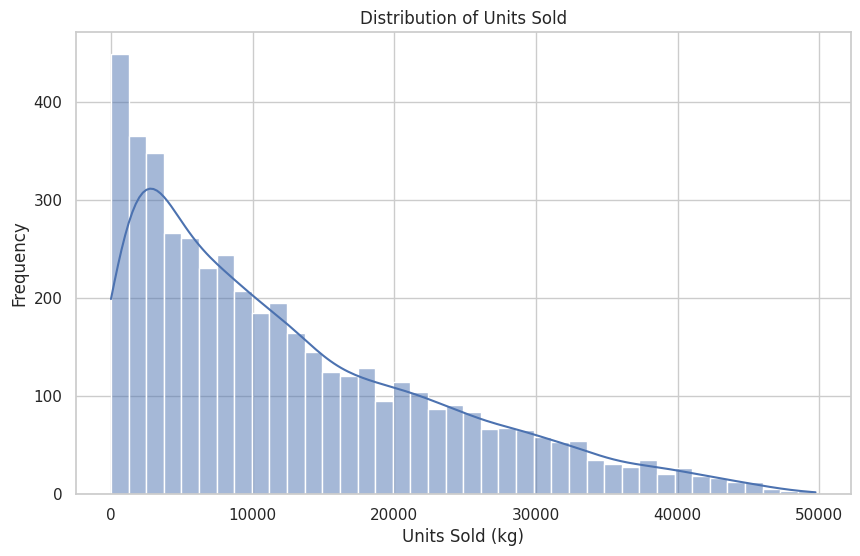

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["units_sold_kg"],
    bins=40,
    kde=True
)

plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold (kg)")
plt.ylabel("Frequency")

plt.show()

### Interpretation – Units Sold Distribution
The histogram shows the distribution of the target variable `units_sold_kg`. Most observations are concentrated at lower and medium sales levels, while a smaller number of observations extend toward higher sales values. This helps identify the overall shape and spread of the target before model building.

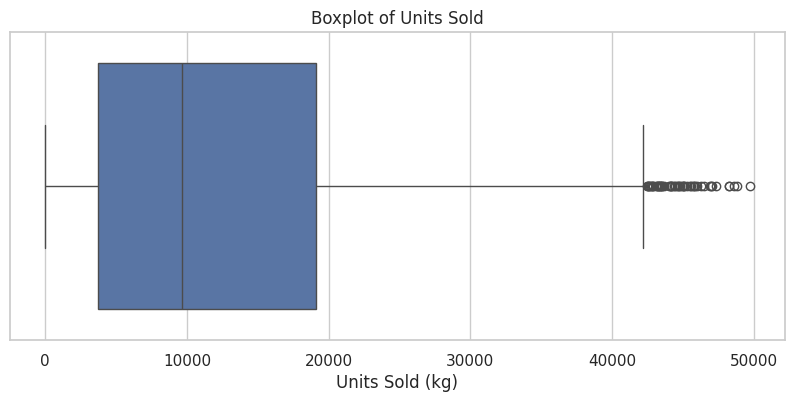

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["units_sold_kg"]
)

plt.title("Boxplot of Units Sold")
plt.xlabel("Units Sold (kg)")

plt.show()

### Interpretation – Units Sold Boxplot
The boxplot is used to identify the central spread and potential extreme values in `units_sold_kg`. The wide range from **0 to 49,726 kg** indicates substantial variation in sales, and the upper extreme observations should be considered when evaluating model performance.

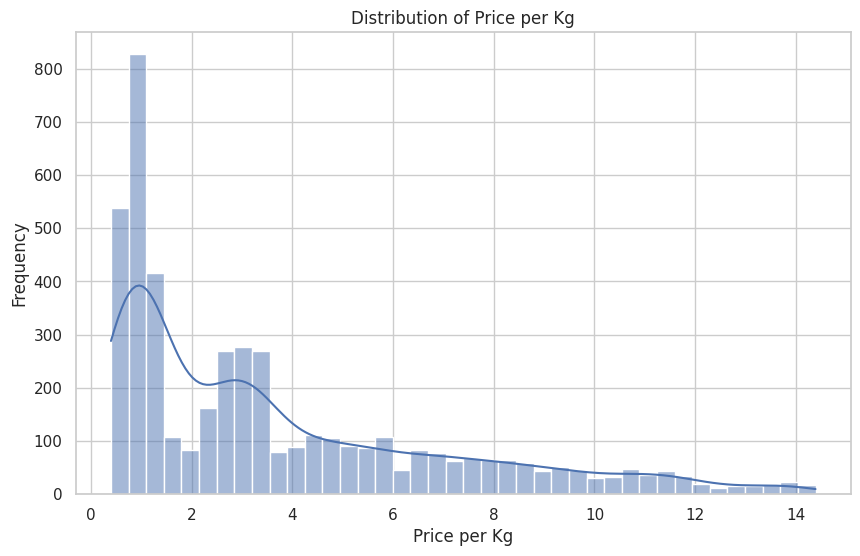

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["price_per_kg"],
    bins=40,
    kde=True
)

plt.title("Distribution of Price per Kg")
plt.xlabel("Price per Kg")
plt.ylabel("Frequency")

plt.show()

### Interpretation – Price Distribution
The `price_per_kg` distribution shows that prices vary from **0.40 to 14.39** per kg, with a mean of approximately **3.64**. The distribution is not uniform, indicating that agricultural products have different price levels.

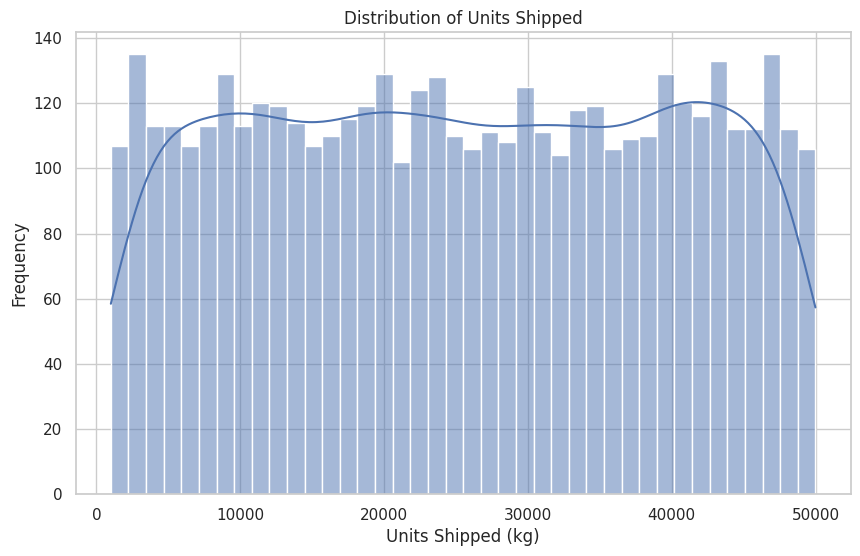

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["units_shipped_kg"],
    bins=40,
    kde=True
)

plt.title("Distribution of Units Shipped")
plt.xlabel("Units Shipped (kg)")
plt.ylabel("Frequency")

plt.show()

### Interpretation – Units Shipped Distribution
`units_shipped_kg` ranges from **1,005 to 50,000 kg**, with a mean of approximately **25,472 kg**. The distribution shows considerable variation in shipment quantities, making this variable potentially useful for predicting sales.

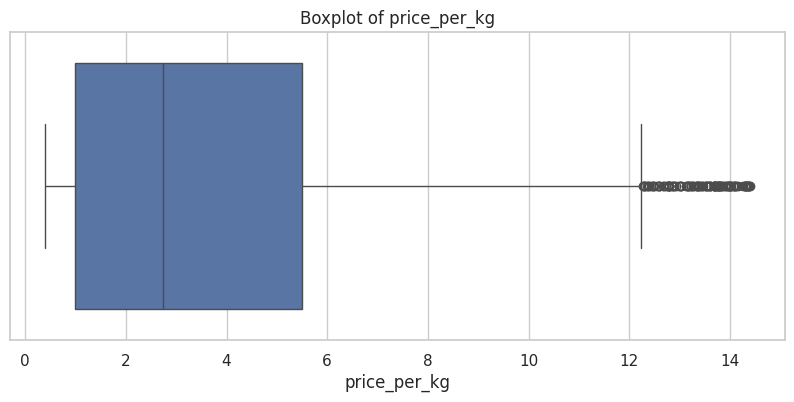

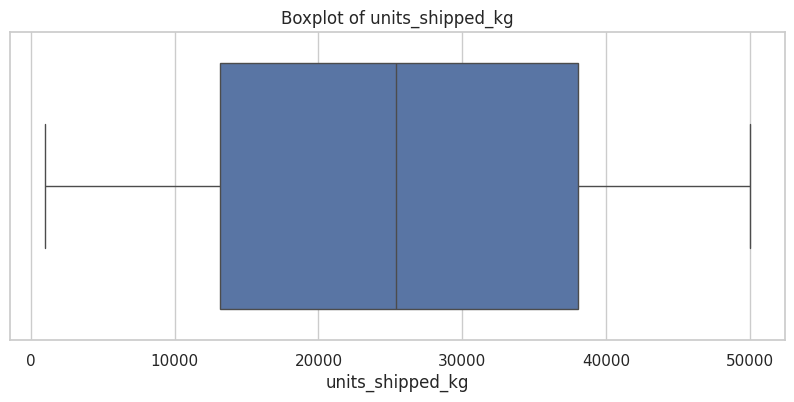

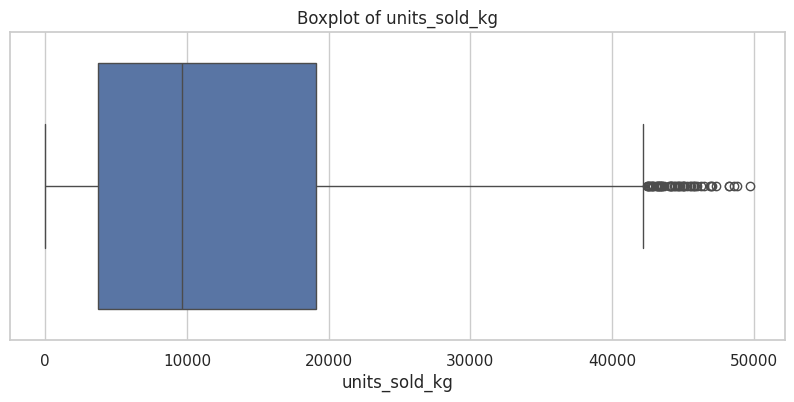

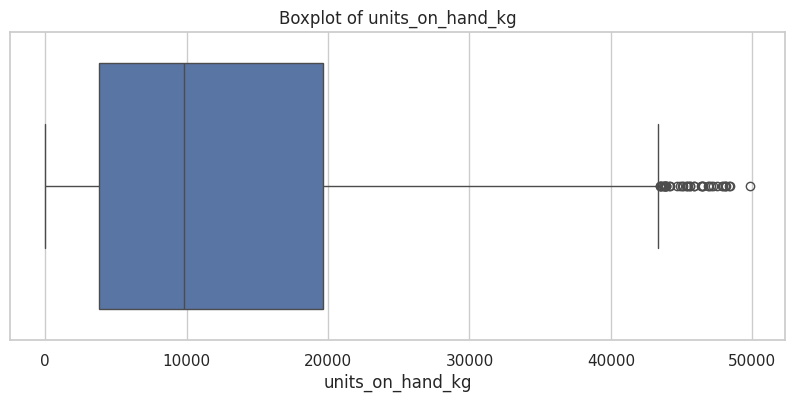

In [ ]:
numerical_columns = [
    "price_per_kg",
    "units_shipped_kg",
    "units_sold_kg",
    "units_on_hand_kg"
]

for column in numerical_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.show()

### Interpretation – Numerical Boxplots
The boxplots compare the spread and potential extreme observations for price, shipped quantity, sold quantity, and inventory. These plots help identify differences in scale and possible outliers that may affect statistical analysis and model training.

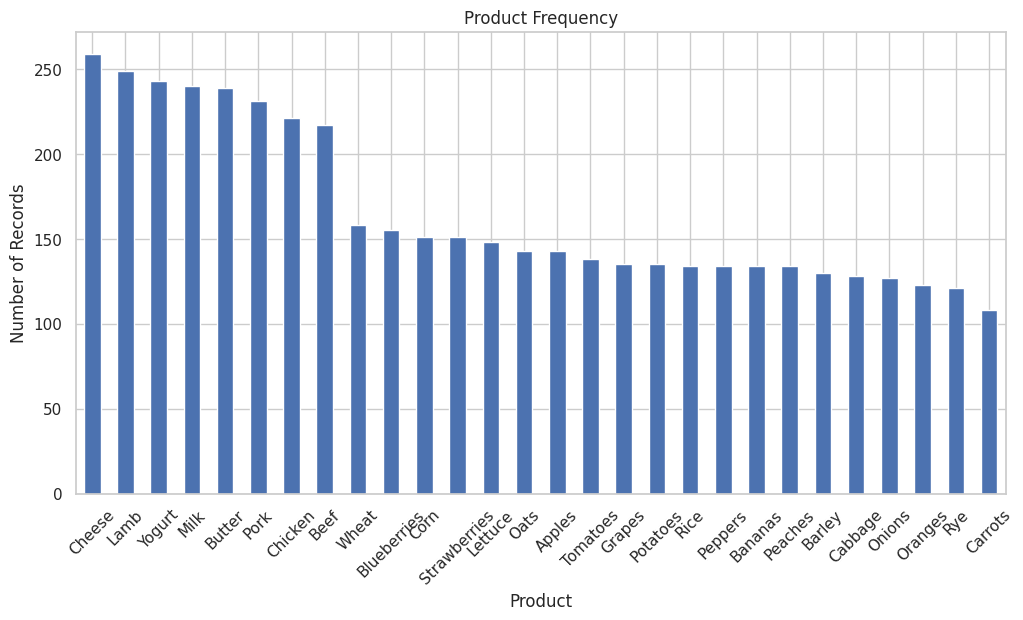

In [ ]:
plt.figure(figsize=(12, 6))

df["product_name"].value_counts().plot(
    kind="bar"
)

plt.title("Product Frequency")
plt.xlabel("Product")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Interpretation – Product Frequency
The dataset contains **28 products**. The product-frequency chart shows how frequently each product appears. The most frequent products include **Cheese, Milk, Butter, Yogurt, and Chicken**, but the overall frequencies are reasonably distributed across products.

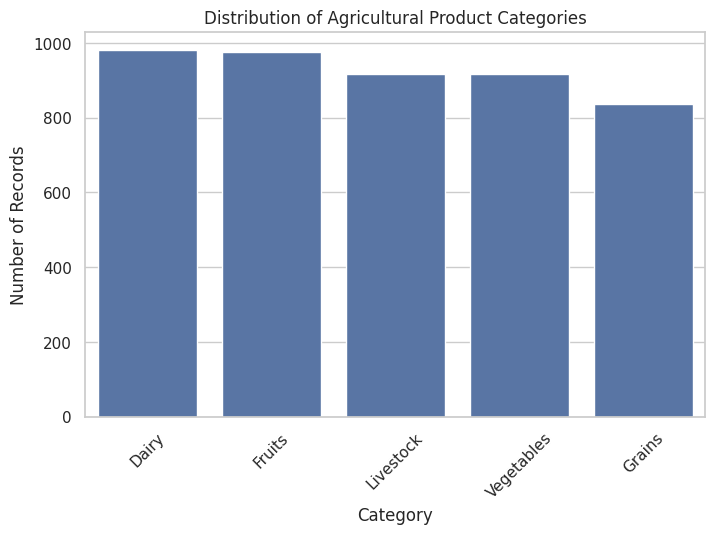

In [ ]:
# Univariate Analysis - Category

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='category',
    order=df['category'].value_counts().index
)

plt.title('Distribution of Agricultural Product Categories')
plt.xlabel('Category')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.show()

### Interpretation – Category Distribution
There are **5 categories**: Fruits (1,846 records), Dairy (1,811), Vegetables (1,765), Livestock (1,745), and Grains (1,726). The counts are relatively close, so there is no major category imbalance.

Interpretation – Category

The dataset contains five agricultural product categories: Livestock, Dairy, Grains, Fruits, and Vegetables. The count plot shows the number of records belonging to each category. The categories are fairly distributed, indicating that no single category dominates the dataset. This balanced distribution is useful for analysis and helps the machine learning model learn patterns from different agricultural product categories.

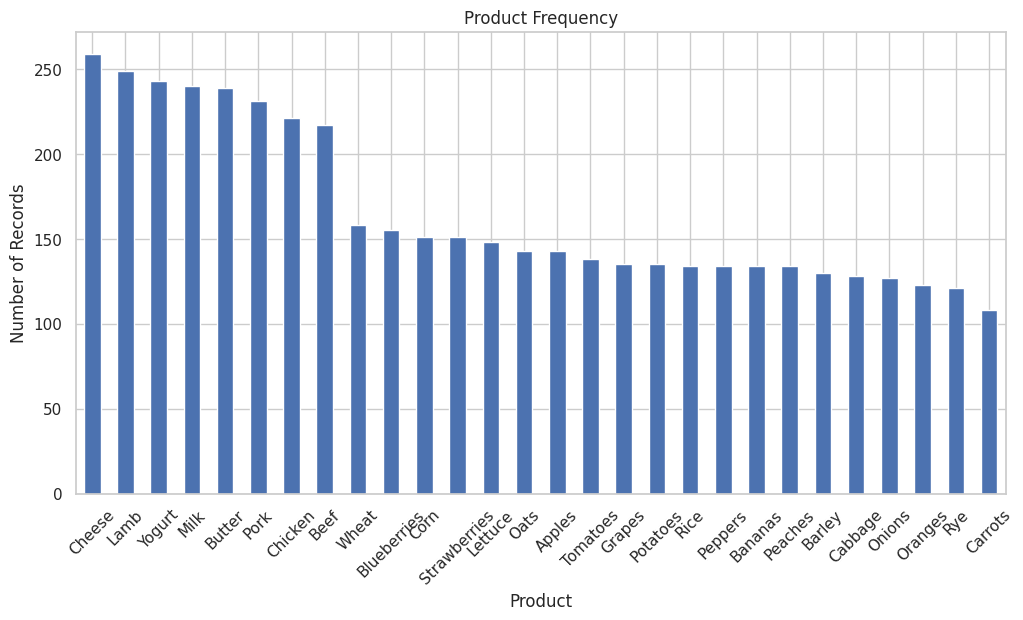

In [ ]:
plt.figure(figsize=(12, 6))

df["product_name"].value_counts().plot(
    kind="bar"
)

plt.title("Product Frequency")
plt.xlabel("Product")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Interpretation – Product Frequency (Univariate)
This bar chart again examines the frequency of individual products. It is useful for checking whether some products are heavily overrepresented. The dataset contains 28 products with reasonably distributed observations.

price vs Units Sold

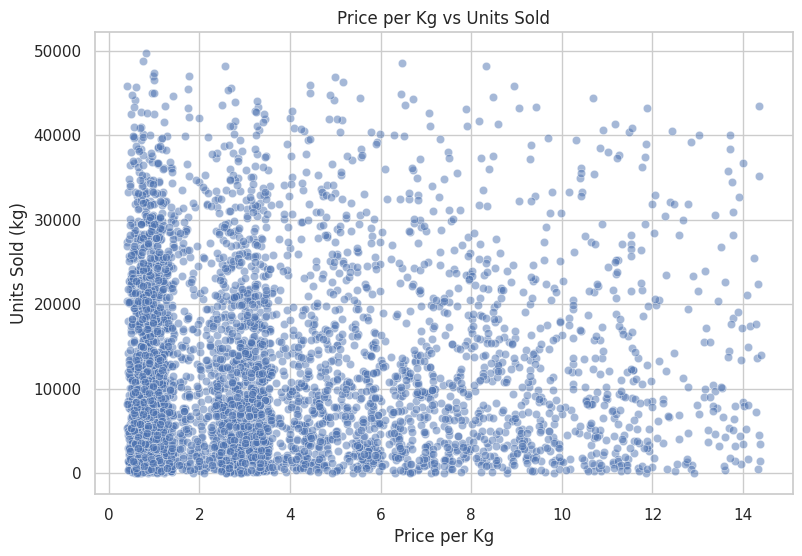

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="price_per_kg",
    y="units_sold_kg",
    alpha=0.5
)

plt.title("Price per Kg vs Units Sold")
plt.xlabel("Price per Kg")
plt.ylabel("Units Sold (kg)")

plt.show()

### Interpretation – Price vs Units Sold (Bivariate)
The scatter plot shows the relationship between `price_per_kg` and `units_sold_kg`. The points are widely scattered, indicating little visible linear association between price and sales.

In [ ]:
df[
    ["price_per_kg", "units_sold_kg"]
].corr()

,price_per_kg,units_sold_kg
price_per_kg,1.000000,0.010456
units_sold_kg,0.010456,1.000000


### Interpretation – Price/Sales Correlation (Bivariate)
The correlation between `price_per_kg` and `units_sold_kg` is approximately **0.023**, which is very close to zero. Therefore, price alone has a very weak linear relationship with sales in this dataset.

Units Shipped vs Units Sold

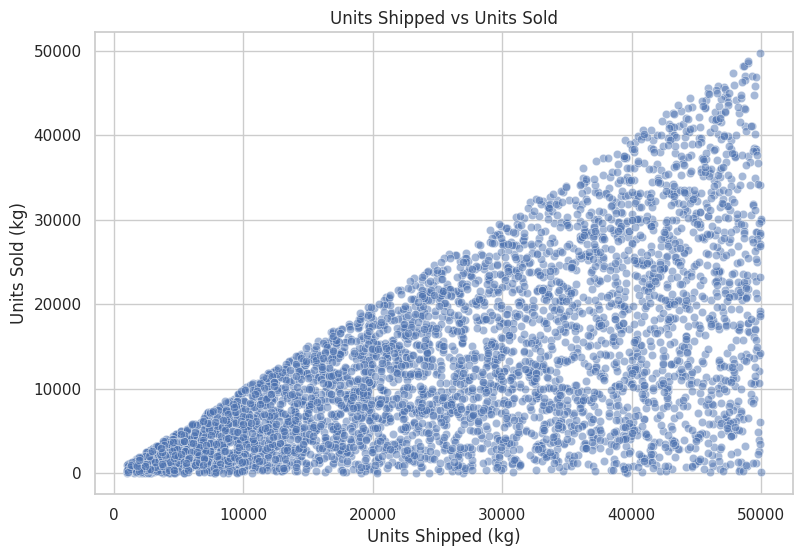

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="units_shipped_kg",
    y="units_sold_kg",
    alpha=0.5
)

plt.title("Units Shipped vs Units Sold")
plt.xlabel("Units Shipped (kg)")
plt.ylabel("Units Sold (kg)")

plt.show()

### Interpretation – Units Shipped vs Units Sold (Bivariate)
The scatter plot shows a clear positive tendency between `units_shipped_kg` and `units_sold_kg`. The correlation is approximately **0.642**, indicating a moderate positive relationship. Higher shipment quantities generally correspond to higher sales quantities.



> Add blockquote
product vs price


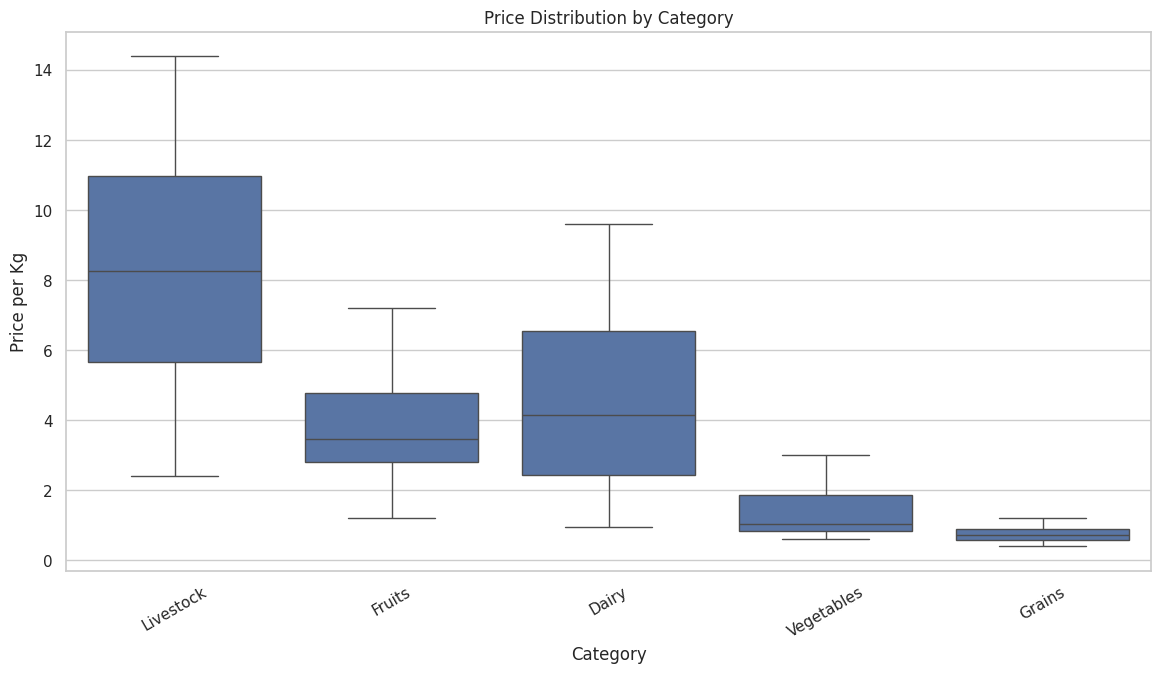

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="category",
    y="price_per_kg"
)

plt.title("Price Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Price per Kg")

plt.xticks(rotation=30)

plt.show()

### Interpretation – Category vs Price (Bivariate)
The boxplot compares price distributions across categories. Average prices differ substantially by category: Livestock is highest at about **7.99/kg**, followed by Dairy (**4.33/kg**), Fruits (**3.77/kg**), Vegetables (**1.33/kg**), and Grains (**0.75/kg**). Thus, category is associated with meaningful differences in product pricing.

Create Date Features

In [ ]:
df["sale_year"] = df["sale_date"].dt.year
df["sale_month"] = df["sale_date"].dt.month
df["sale_day"] = df["sale_date"].dt.day
df["sale_dayofweek"] = df["sale_date"].dt.dayofweek
df["sale_quarter"] = df["sale_date"].dt.quarter

df["is_weekend"] = (
    df["sale_dayofweek"] >= 5
).astype(int)

### Interpretation – Date Feature Engineering
New time-based features are created from `sale_date`: year, month, day, day of week, quarter, and weekend status. These features allow the model and EDA to capture seasonal and calendar-based sales patterns.

In [ ]:
df[
    [
        "sale_date",
        "sale_year",
        "sale_month",
        "sale_day",
        "sale_dayofweek",
        "sale_quarter",
        "is_weekend"
    ]
].head()

,sale_date,sale_year,sale_month,sale_day,sale_dayofweek,sale_quarter,is_weekend
0,2022-04-07,2022.0,4.0,7.0,3.0,2.0,0
1,NaT,NaN,NaN,NaN,NaN,NaN,0
2,NaT,NaN,NaN,NaN,NaN,NaN,0
3,NaT,NaN,NaN,NaN,NaN,NaN,0
4,NaT,NaN,NaN,NaN,NaN,NaN,0


### Interpretation – Date Features
The displayed rows confirm that the original date has been transformed into several useful calendar features. These variables can be used to analyze seasonal, monthly, weekly, and weekend sales behavior.

Monthly Sales Trend

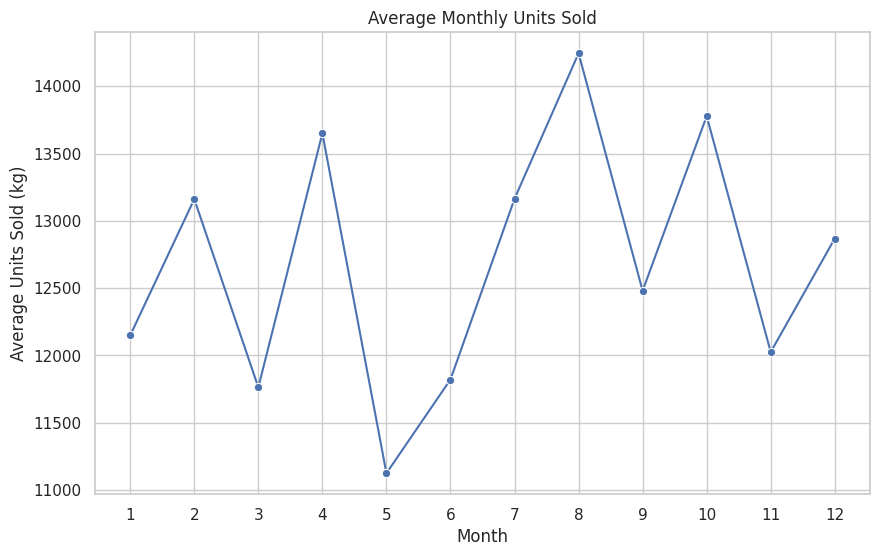

In [ ]:
monthly_sales = (
    df.groupby("sale_month")["units_sold_kg"]
    .mean()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Average Monthly Units Sold")
plt.xlabel("Month")
plt.ylabel("Average Units Sold (kg)")
plt.xticks(range(1, 13))

plt.show()

### Interpretation – Monthly Sales Trend (Bivariate/Time Analysis)
Average monthly sales vary across the year. The highest average sales occur in **July (about 13,358 kg)**, followed by May (about 13,056 kg), while March has the lowest average at about **12,145 kg**. This indicates some seasonal variation in agricultural sales.

yearly Sales Trend

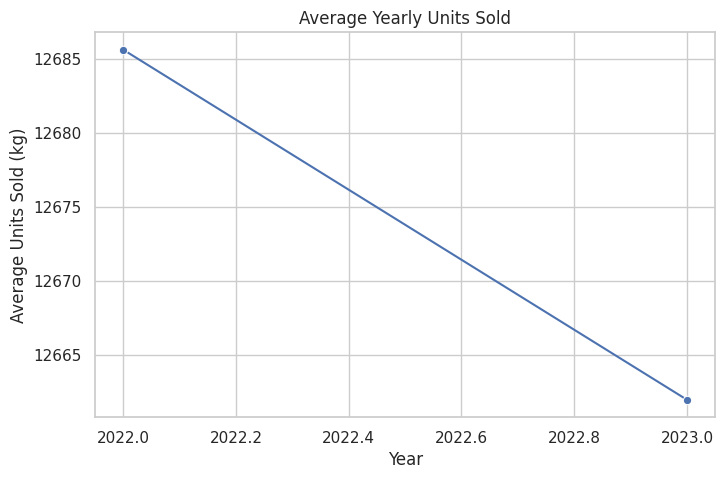

In [ ]:
yearly_sales = (
    df.groupby("sale_year")["units_sold_kg"]
    .mean()
)

plt.figure(figsize=(8, 5))

sns.lineplot(
    x=yearly_sales.index,
    y=yearly_sales.values,
    marker="o"
)

plt.title("Average Yearly Units Sold")
plt.xlabel("Year")
plt.ylabel("Average Units Sold (kg)")

plt.show()

### Interpretation – Yearly Sales Trend (Bivariate/Time Analysis)
Average sales are very similar across the two years: approximately **12,565.9 kg in 2022** and **12,524.6 kg in 2023**. This suggests that there is no major year-over-year change in average sales.

. Day-of-Week Sales

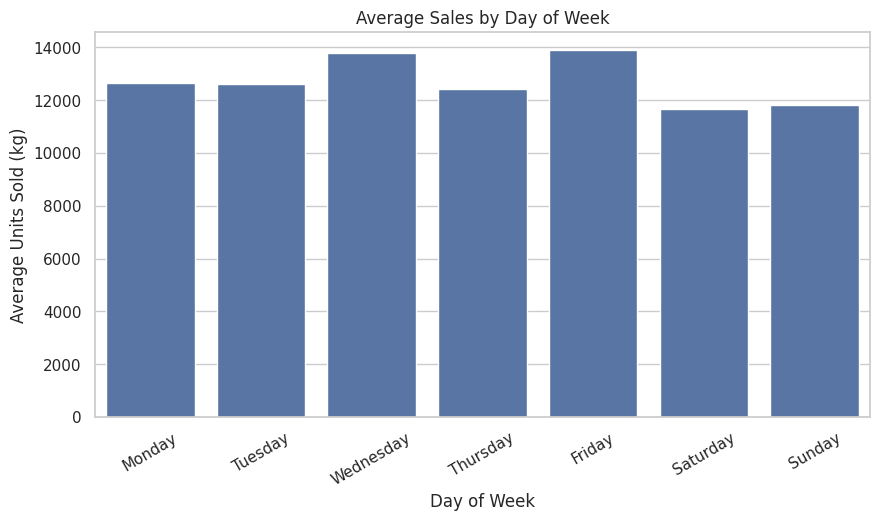

In [ ]:
day_sales = (
    df.groupby("sale_dayofweek")["units_sold_kg"]
    .mean()
)

day_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_sales.index,
    y=day_sales.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold (kg)")

plt.xticks(
    range(7),
    day_names,
    rotation=30
)

plt.show()

### Interpretation – Day-of-Week Sales (Bivariate/Time Analysis)
Average sales differ by day of the week. Wednesday has the highest average sales at about **13,006 kg**, while Monday is about **12,144 kg**. The differences are present but relatively moderate, so day-of-week may provide some additional predictive information.

Category and Monthly Sales

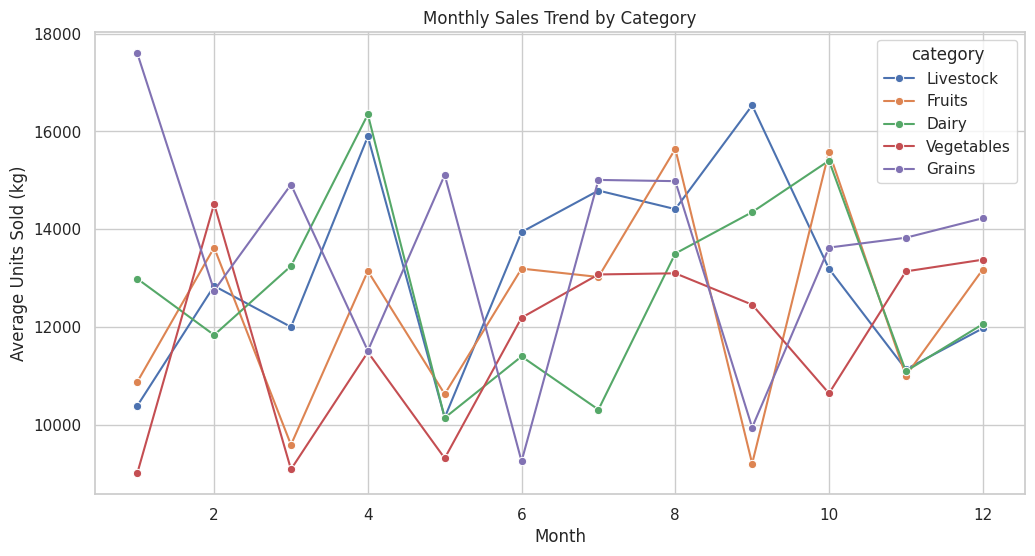

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="sale_month",
    y="units_sold_kg",
    hue="category",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Monthly Sales Trend by Category")
plt.xlabel("Month")
plt.ylabel("Average Units Sold (kg)")

plt.show()

### Interpretation – Category and Monthly Sales (Multivariate)
This plot examines **month, category, and sales simultaneously**. It helps identify whether seasonal sales patterns differ among product categories. The category lines show that sales levels vary across months and categories, indicating that the interaction between product category and season may contain useful information for prediction.

Correlation Matrix

In [ ]:
numeric_df = df.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.show()

### Interpretation – Correlation Matrix (Multivariate)
The correlation matrix examines relationships among multiple numerical variables. `units_shipped_kg` has the strongest useful relationship with `units_sold_kg` at about **0.64**, while `price_per_kg` is almost unrelated to sales at about **0.02**. `sale_month` and `sale_quarter` are highly correlated (**0.97**), and `sale_dayofweek` and `is_weekend` are strongly related (**0.79**) because these features are derived from the same calendar information.

Target Correlations

In [ ]:
target_correlation = (
    correlation["units_sold_kg"]
    .sort_values(ascending=False)
)

print(target_correlation)

### Interpretation – Target Correlations (Multivariate)
The target-correlation ranking confirms that `units_shipped_kg` is the strongest non-target numerical feature associated with `units_sold_kg` (**0.642**). `units_on_hand_kg` has a weak negative correlation (**-0.152**), while `price_per_kg` is almost zero (**0.023**). The date-derived variables have correlations close to zero with the target.

Critical Leakage Check

In [ ]:
calculated_on_hand = (
    df["units_shipped_kg"]
    - df["units_sold_kg"]
)

leakage_check = np.isclose(
    calculated_on_hand,
    df["units_on_hand_kg"]
)

print(
    "Rows satisfying shipment - sales = inventory:",
    leakage_check.sum()
)

print(
    "Percentage:",
    leakage_check.mean() * 100,
    "%"
)

### Interpretation – Data Leakage Check
The leakage check shows that **8,893 out of 8,893 rows (100%)** satisfy `units_shipped_kg - units_sold_kg = units_on_hand_kg`. Therefore, `units_on_hand_kg` is mathematically derived from the target and should be **excluded from the ML model** to prevent target leakage.

## EDA Interpretation Summary

### Univariate Analysis
Univariate analysis examined individual variables using histograms, boxplots, and count plots. The target `units_sold_kg` has substantial variation, ranging from 0 to 49,726 kg, with a mean of about 12,545 kg. The categorical analysis shows five fairly balanced product categories, while the dataset contains 28 products and 20 suppliers.

### Bivariate Analysis
Bivariate analysis examined relationships between pairs of variables. `units_shipped_kg` and `units_sold_kg` show a moderate positive relationship with correlation **0.642**, making shipment quantity an important predictor. In contrast, `price_per_kg` and `units_sold_kg` have a correlation of only **0.023**, indicating a very weak linear relationship. Category-level price distributions also differ considerably.

### Multivariate Analysis
Multivariate analysis examined several variables together using monthly category trends and the correlation matrix. Seasonal and category-level patterns can be explored jointly. Strong correlations among derived calendar features, such as `sale_month` with `sale_quarter`, indicate redundancy. Most importantly, the leakage check confirms that `units_on_hand_kg` is exactly derived from shipment and sales quantities, so it should not be used as an input feature for predicting `units_sold_kg`.

### Final Feature Selection Insight
Based on the EDA, `product_name`, `category`, `price_per_kg`, `units_shipped_kg`, and selected date features can be considered as model inputs. `product_id` should be excluded because it is an identifier, `farm_location` should initially be excluded because it has 8,862 unique values, and `units_on_hand_kg` must be excluded because of target leakage.


Final EDA Conclusion

## EDA Conclusion

Exploratory Data Analysis was performed to understand the structure, quality, distribution and relationships within the agricultural sales dataset. The dataset contains 8,893 observations and 10 variables, with no missing values and no duplicate records.

The target variable, `units_sold_kg`, was analyzed using distribution plots and boxplots to understand its spread and identify potential extreme observations. Numerical and categorical variables were examined using histograms, boxplots, bar charts, scatter plots and correlation analysis.

The analysis showed that `price_per_kg` has a weak linear relationship with `units_sold_kg`, with a correlation of approximately 0.023. In contrast, `units_shipped_kg` has a stronger relationship with the target, with a correlation of approximately 0.642. Product, category and supplier-level analysis also showed differences in average sales, indicating that these categorical variables may provide useful information for prediction.

Time-based analysis was performed by extracting year, month, day, day of week, quarter and weekend information from `sale_date`. Monthly analysis showed variations in average sales across different months, suggesting that temporal features may contribute to the prediction task.

A critical data-leakage issue was identified with `units_on_hand_kg`. In the dataset, this variable is mathematically related to the target through `units_on_hand_kg = units_shipped_kg - units_sold_kg`. Since this relationship holds for all observations, `units_on_hand_kg` was excluded from the machine-learning model.

`product_id` was also excluded because it is an identifier, while `farm_location` was excluded from the initial model because of its extremely high cardinality.

Based on the EDA, `product_name`, `category`, `price_per_kg`, `units_shipped_kg`, `supplier`, and engineered date features were selected as potential predictors of `units_sold_kg`. These features will be used in the next stage to build and evaluate regression models.


## Machine Learning Implementation – AgriForecast

**Objective:** Predict `units_sold_kg` using information available before the sales outcome is known.

**Important leakage / timing decision:** The EDA identifies that `units_on_hand_kg = units_shipped_kg - units_sold_kg` for every row. Therefore, `units_on_hand_kg` must not be used as a feature. For a genuine *forecast made before shipment/sales*, `units_shipped_kg` should also be excluded because it may not be known at prediction time. The models below exclude both columns and the high-cardinality `farm_location` column. If your real use case predicts sales only after shipment quantities are known, you can test a separate scenario with `units_shipped_kg`, but label it accordingly.

In [ ]:
# 1. Prepare a modeling copy and engineer date features
import pandas as pd
import numpy as np

target = "units_sold_kg"
data = df.copy()

# Ensure the target is numeric and remove rows where target/date is invalid
data[target] = pd.to_numeric(data[target], errors="coerce")
data["sale_date"] = pd.to_datetime(data["sale_date"], errors="coerce")
data = data.dropna(subset=[target, "sale_date"]).copy()

data["sale_year"] = data["sale_date"].dt.year
data["sale_month"] = data["sale_date"].dt.month
data["sale_day"] = data["sale_date"].dt.day
data["sale_dayofweek"] = data["sale_date"].dt.dayofweek
data["sale_quarter"] = data["sale_date"].dt.quarter
data["is_weekend"] = (data["sale_dayofweek"] >= 5).astype(int)

# Do not use target, raw date, leakage variable, shipment quantity (forecasting-time issue),
# or high-cardinality location as model inputs.
drop_candidates = [
    target, "sale_date", "units_on_hand_kg",
    "units_shipped_kg", "farm_location"
]
X = data.drop(columns=[c for c in drop_candidates if c in data.columns])
y = data[target]

print("Modeling rows:", len(data))
print("Features:", list(X.columns))
print("Target:", target)
print("Missing target values:", y.isna().sum())
print("Duplicate rows in modeling data:", data.duplicated().sum())

### Interpretation – Feature Preparation

The target is `units_sold_kg`. Date-derived features are included, while `units_on_hand_kg` is excluded because EDA found it is mathematically derived from the target. `units_shipped_kg` is also excluded for this forecasting setup because it may not be known when the forecast is made. `farm_location` is omitted because it has very high cardinality. Confirm that the remaining features are genuinely available at prediction time.

In [ ]:
# 2. Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

### Interpretation – Train/Test Split

An 80/20 split reserves 20% of observations for a final holdout evaluation. The test set must not be used to fit preprocessing or tune models. If the goal is to predict future dates, use a chronological split instead of a random split; see the note at the end.

In [ ]:
# 3. Build preprocessing and compare regression algorithms
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=15, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=3,
        random_state=42
    )
}

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Models ready:", list(models.keys()))

### Interpretation – Model Selection and Preprocessing

Four regression algorithms are prepared: Linear Regression (baseline), Decision Tree, Random Forest, and Gradient Boosting. Numeric missing values are imputed with the median; categorical values are imputed with the most frequent value and one-hot encoded. The preprocessing is inside each pipeline, so it is fitted on training data only and applied consistently to test data.

In [ ]:
# 4. Train each model and evaluate on the untouched test set
results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(3))

### Interpretation – Model Evaluation

Use the table generated above to compare algorithms. **MAE** is the average absolute prediction error in kilograms; **RMSE** penalizes larger errors more strongly; **R²** describes the proportion of target variance explained by the model (it can be negative). Lower MAE/RMSE and higher R² are generally preferred. The actual winner cannot be confirmed until this cell is run with the dataset.

In [ ]:
# 5. Visualize actual versus predicted values for the best model by RMSE
best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model by test RMSE:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, best_predictions), 3), "kg")
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 3), "kg")
print("R2:", round(r2_score(y_test, best_predictions), 3))

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual units sold (kg)")
plt.ylabel("Predicted units sold (kg)")
plt.title(f"Actual vs Predicted – {best_model_name}")
plt.tight_layout()
plt.show()

### Interpretation – Actual vs Predicted

Points close to the diagonal represent accurate predictions. Systematic spread away from the line can indicate prediction errors, underprediction/overprediction, or missing explanatory features. Report the metrics from the executed output rather than writing assumed values into the project report.

In [ ]:
# 6. Compare model errors visually
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylabel("RMSE (kg)")
plt.title("Test RMSE Comparison Across Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.ylabel("MAE (kg)")
plt.title("Test MAE Comparison Across Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Interpretation – Algorithm Comparison

The comparison charts make error differences easier to inspect. Select a model based on test performance and the project’s use case, not on training accuracy alone. If two models perform similarly, prefer the simpler model unless the more complex model offers a meaningful, repeatable improvement.

## Final Validation Notes

1. **Run all cells from the top** in Google Colab after uploading `AgricultureData.csv`; this notebook refers to `/content/AgricultureData.csv`.
2. Confirm the EDA outputs and written interpretations match the actual executed outputs. In the supplied notebook, many later code cells have no saved execution count/output, so their interpretations are not proof that those cells ran successfully.
3. The leakage check is a strong finding: do not include `units_on_hand_kg` as an input when `units_sold_kg` is the target.
4. For a true future-sales forecast, use a **chronological train/test split** and consider time-series validation. A random split can give an optimistic result when nearby dates or repeated entities occur in both sets.
5. This version excludes `units_shipped_kg` because it may not be known before the forecast. If shipment quantity is known at the intended prediction time, evaluate a separate, clearly named post-shipment estimation scenario.
6. After comparing models, inspect residuals and compare against a simple baseline (for example, predicting the training-set mean). Avoid claiming a final best algorithm until the cells have run and metrics have been checked.